# 像素腦 EP13｜為什麼不把 GTA 6 做成 60 幀？
影片裡的迷你城市和數字都是這本筆記本跑出來的。這是我們自己寫的小程式，**不是 GTA 6 的程式**；時間是在你這台電腦上實測，每台電腦、每次執行都會有點不同。

貓咪照片：AdinaVoicu，CC0，Wikimedia Commons。

In [1]:
import json, os, time, urllib.request
from pathlib import Path
import numpy as np
from PIL import Image

if not os.path.exists("cat.png"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/pixelbraintw/pixelbrain-code/main/ep13-gta6-fps/cat.png", "cat.png")
R = {}
rng = np.random.default_rng(13)

## 1. 每一格有多少時間
1000 毫秒除以幀數。

In [2]:
# 1. 每格時間預算
R["budget_ms"] = {str(f): round(1000 / f, 2) for f in (24, 30, 40, 45, 60, 120)}

## 2. 翻頁動畫：同一顆球，30 幀和 60 幀每一步在哪

In [3]:
# 2. 翻頁動畫：一顆球 1 秒從左跑到右，30 幀和 60 幀各畫在哪
R["ball30"] = [round(i / 30, 4) for i in range(31)]
R["ball60"] = [round(i / 60, 4) for i in range(61)]

## 3. 迷你城市：行人互相閃避（處理器的工作）
`crowd_naive` 每兩個人都比一次；`crowd_grid` 先把城市切成格子，只跟同格和隔壁格比。改改看 `RADIUS`、`WORLD`，或在 `R["crowd_N"]` 加更多人。注意：`crowd_naive` 在 8000 人以上會非常慢。

In [4]:
# 3. 迷你城市：N 個行人，每個人看附近的人並避開（CPU 的工作）
WORLD, RADIUS = 1000.0, 20.0
def crowd_naive(pos):
    d = pos[:, None, :] - pos[None, :, :]                 # 每兩個人都比一次
    dist2 = (d ** 2).sum(-1)
    near = (dist2 < RADIUS ** 2) & (dist2 > 0)
    push = (d * near[..., None]).sum(1)
    return pos + 0.01 * push

def crowd_grid(pos):
    cell = (pos // RADIUS).astype(int)                       # 先分格子，只跟同格與隔壁格比
    key = cell[:, 0] * 10000 + cell[:, 1]
    order = np.argsort(key); ks = key[order]
    buckets = {}
    starts = np.flatnonzero(np.r_[True, ks[1:] != ks[:-1]])
    ends = np.r_[starts[1:], len(ks)]
    for s, e in zip(starts, ends):
        buckets[ks[s]] = order[s:e]
    out = pos.copy()
    for k, idx in buckets.items():
        cx, cy = divmod(k, 10000)
        nb = [buckets[(cx + a) * 10000 + cy + b] for a in (-1, 0, 1) for b in (-1, 0, 1) if (cx + a) * 10000 + cy + b in buckets]
        nb = np.concatenate(nb)
        d = pos[idx][:, None, :] - pos[nb][None, :, :]
        dist2 = (d ** 2).sum(-1)
        near = (dist2 < RADIUS ** 2) & (dist2 > 0)
        out[idx] += 0.01 * (d * near[..., None]).sum(1)
    return out

def timeit(f, *a, rep=15):
    f(*a)
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); f(*a); ts.append(time.perf_counter() - t0)
    return round(1000 * float(np.min(ts)), 2)   # 取最快的一次，排除雲端電腦被別的程式打斷

R["crowd_N"] = [250, 500, 1000, 2000, 4000, 8000]
R["crowd_naive_ms"] = []; R["crowd_grid_ms"] = []
for n in R["crowd_N"]:
    pos = rng.uniform(0, WORLD, (n, 2))
    R["crowd_naive_ms"].append(timeit(crowd_naive, pos) if n <= 4000 else None)
    R["crowd_grid_ms"].append(timeit(crowd_grid, pos))
R["pairs"] = {str(n): n * (n - 1) // 2 for n in R["crowd_N"]}

## 4. 畫圖（GPU 的工作，這裡用處理器模擬，只看比例）

In [5]:
# 4. 畫圖（GPU 的工作，這裡用 CPU 模擬）：每個像素算一次光照
def render(w, h):
    ys, xs = np.mgrid[0:h, 0:w].astype(np.float32)
    u, v = xs / w, ys / h
    n = np.sin(u * 40) * np.cos(v * 30)
    light = np.clip(0.5 + 0.5 * n, 0, 1)
    img = np.stack([light * (0.6 + 0.4 * u), light * 0.8, light * (0.5 + 0.5 * v)], -1)
    for _ in range(3):                      # 再疊幾層效果（陰影、反光、霧）
        img = 0.9 * img + 0.1 * np.sqrt(img + 0.01)
    return img
RES = {"720p": (1280, 720), "1080p": (1920, 1080), "1440p": (2560, 1440), "4K": (3840, 2160)}
R["render_ms"] = {k: timeit(render, *wh, rep=5) for k, wh in RES.items()}
R["pixels"] = {k: w * h for k, (w, h) in RES.items()}
R["px_ratio_4k_1440"] = round(R["pixels"]["4K"] / R["pixels"]["1440p"], 2)

## 5. 幾個人就塞滿一格
你的電腦和影片裡的雲端電腦不一樣，數字會不同。

In [6]:
# 5. 迷你城市要多少人，就塞滿一格的時間（grid 版，線性內插）
def cross(limit):
    N, T = R["crowd_N"], R["crowd_grid_ms"]
    for i in range(1, len(N)):
        if T[i] >= limit:
            return int(round(N[i-1] + (N[i]-N[i-1]) * (limit - T[i-1]) / (T[i] - T[i-1]), -2))
R["cross"] = {"16.7": cross(16.67), "33.3": cross(33.33)}
R["naive_vs_grid_4000"] = round(R["crowd_naive_ms"][4] / R["crowd_grid_ms"][4], 1)
R["naive_2000_to_4000"] = round(R["crowd_naive_ms"][4] / R["crowd_naive_ms"][3], 1)

## 6. 60Hz、120Hz 電視上，每張畫面停幾次刷新

In [7]:
# 6. 60Hz、120Hz 電視上，每格停留幾次刷新
def cadence(fps, hz, n=12):
    shown = []
    for k in range(n):
        t0, t1 = k / fps, (k + 1) / fps
        r0, r1 = int(np.ceil(t0 * hz - 1e-9)), int(np.ceil(t1 * hz - 1e-9))
        shown.append(r1 - r0)
    return shown
R["cadence"] = {f"{f}@{h}": cadence(f, h) for f, h in ((30, 60), (45, 60), (60, 60), (30, 120), (40, 120), (60, 120))}
R["hold_ms"] = {k: [round(1000 * x / int(k.split('@')[1]), 1) for x in v] for k, v in R["cadence"].items()}

## 7. 阿姆達爾定律：加核心能快幾倍

In [8]:
# 7. 處理器加核心：有一部分一定要照順序（阿姆達爾定律）
R["amdahl"] = {str(p): {str(c): round(1 / ((1 - p) + p / c), 2) for c in (1, 2, 4, 8, 16)} for p in (0.5, 0.8, 0.95)}

## 8. 縮小再放大的貓咪

In [9]:
# 9. 縮小再放大：貓咪照片當成 4K 原圖，先用 2/3 大小算（像 1440p），再放大回來
cat = Image.open("cat.png").convert("RGB")
W, H = cat.size
small = cat.resize((W * 2 // 3, H * 2 // 3), Image.BICUBIC)
near = small.resize((W, H), Image.NEAREST)
bic = small.resize((W, H), Image.BICUBIC)
def psnr(a, b):
    a = np.asarray(a, np.float64); b = np.asarray(b, np.float64)
    return round(float(10 * np.log10(255 ** 2 / ((a - b) ** 2).mean())), 2)
R["upscale_psnr"] = {"nearest": psnr(cat, near), "bicubic": psnr(cat, bic)}
od = Path("out"); od.mkdir(exist_ok=True)
box = (330, 250, 530, 450)   # 眼睛附近放大看
for name, im in (("orig", cat), ("small", small.resize((W, H), Image.NEAREST)), ("nearest", near), ("bicubic", bic)):
    im.crop(box).resize((600, 600), Image.NEAREST).save(od / f"crop_{name}.png")
small.save(od / "small.png")
R["cat_size"] = [W, H]; R["small_size"] = list(small.size)

## 結果

In [10]:
for k in ("budget_ms", "crowd_naive_ms", "crowd_grid_ms", "render_ms", "cross", "naive_vs_grid_4000", "hold_ms", "amdahl", "upscale_psnr"):
    print(k, R[k])

budget_ms {'24': 41.67, '30': 33.33, '40': 25.0, '45': 22.22, '60': 16.67, '120': 8.33}
crowd_naive_ms [2.07, 8.89, 35.89, 160.61, 676.61, None]
crowd_grid_ms [3.72, 5.36, 12.43, 22.43, 36.54, 53.66]
render_ms {'720p': 38.5, '1080p': 101.08, '1440p': 238.44, '4K': 644.21}
cross {'16.7': 1400, '33.3': 3500}
naive_vs_grid_4000 18.5
hold_ms {'30@60': [33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3], '45@60': [33.3, 16.7, 16.7, 33.3, 16.7, 16.7, 33.3, 16.7, 16.7, 33.3, 16.7, 16.7], '60@60': [16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7], '30@120': [33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3, 33.3], '40@120': [25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0], '60@120': [16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7, 16.7]}
amdahl {'0.5': {'1': 1.0, '2': 1.33, '4': 1.6, '8': 1.78, '16': 1.88}, '0.8': {'1': 1.0, '2': 1.67, '4': 2.5, '8': 3.33, '16': 4.0}, '0.95': {'1': 1.0, '2': 1

## 畫出來看看

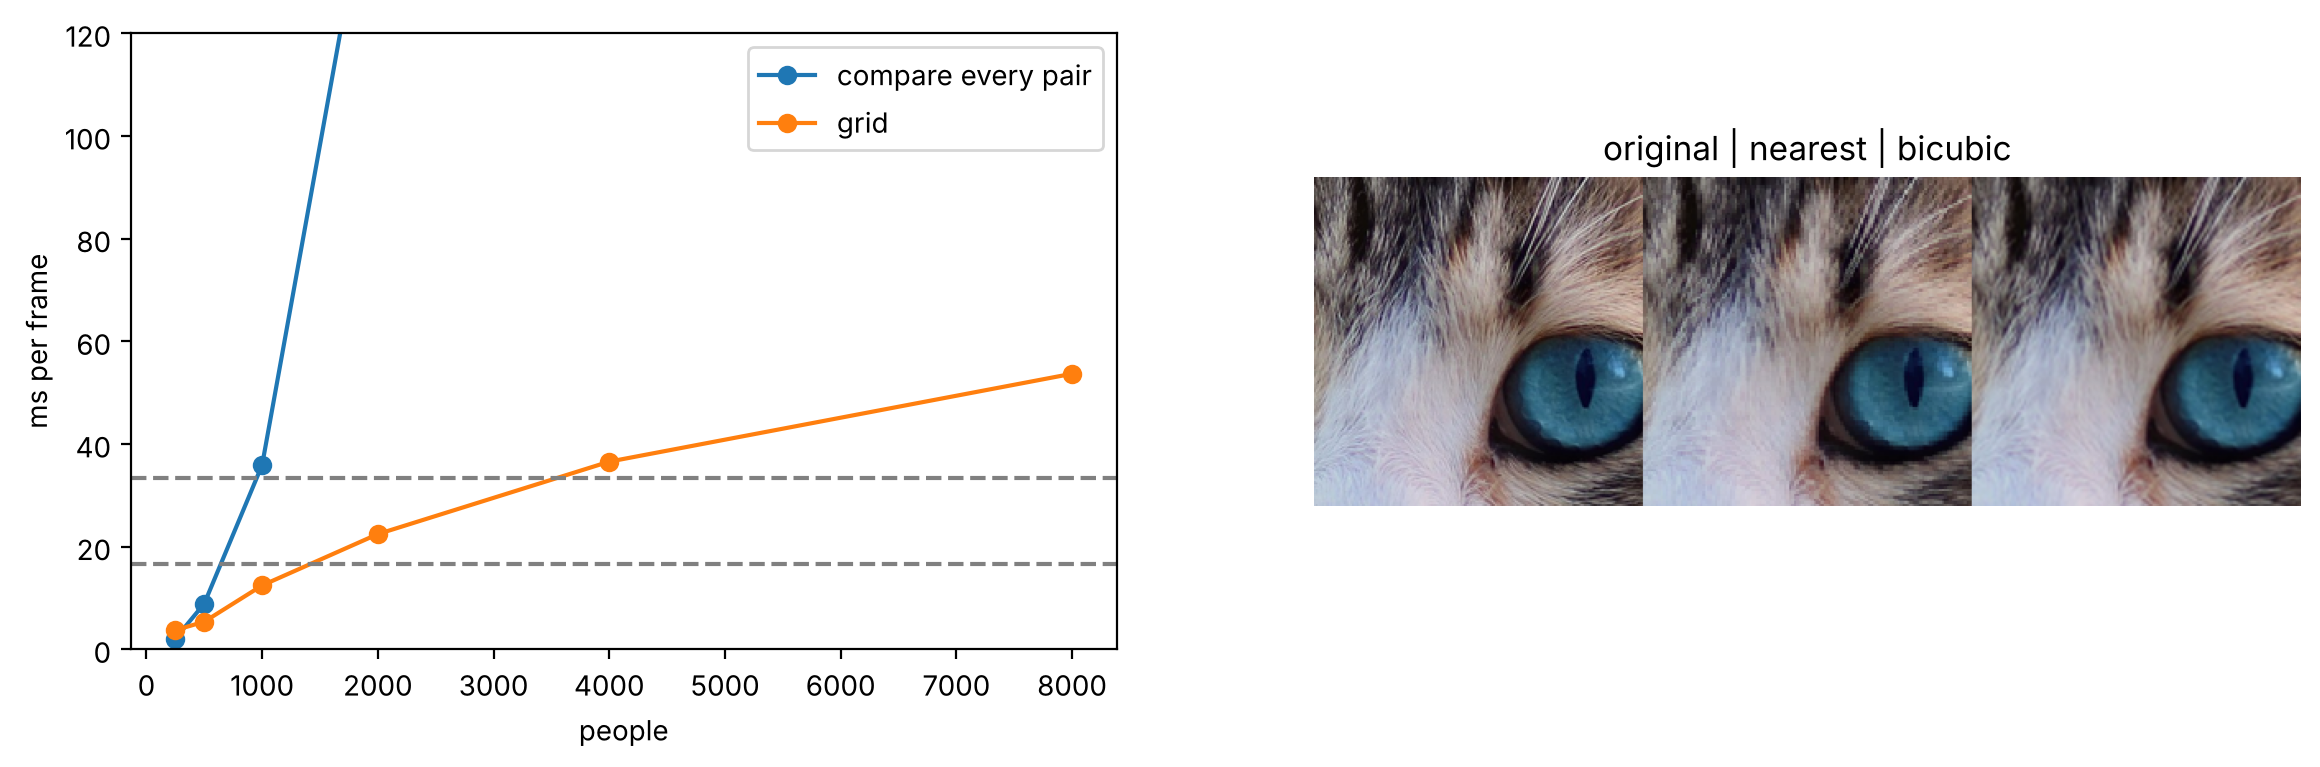

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
N = R["crowd_N"]
ax[0].plot(N[:len([x for x in R["crowd_naive_ms"] if x])], [x for x in R["crowd_naive_ms"] if x], "o-", label="compare every pair")
ax[0].plot(N, R["crowd_grid_ms"], "o-", label="grid")
for v in (16.67, 33.33): ax[0].axhline(v, ls="--", color="gray")
ax[0].set_ylim(0, 120); ax[0].set_xlabel("people"); ax[0].set_ylabel("ms per frame"); ax[0].legend()
ims = [Image.open(f"out/crop_{n}.png") for n in ("orig", "nearest", "bicubic")]
ax[1].imshow(np.hstack([np.asarray(i) for i in ims])); ax[1].set_title("original | nearest | bicubic"); ax[1].axis("off")
plt.show()

## 🧪 自己玩玩看

1. 把 `RADIUS` 改成 40（每個人看得更遠），幾個人就塞滿 16.7 毫秒？
2. 在 `R["crowd_N"]` 加上 16000，分格子的版本也撐得住嗎？
3. 把阿姆達爾定律的 `p` 改成 0.99，16 核能快幾倍？
4. 把貓咪縮小成 1/2 再放大，鋸齒和模糊會更明顯嗎？

有問題歡迎到影片留言區問像素腦！